# Top-five ban: which open models obey, and where do the survivors land in activation space?

**Artifact:** iteration-8 experiment *"Which open models obey a five-algorithm ban"* from the algorithm-choice study on the **T1 grid-path task**. Every prompt asks for a Python function `solve(grid, start, goal)` that returns any valid path on a 4-connected grid with walls.

**The question.** Asked plainly, almost every open model writes BFS (or DFS). What happens when the prompt *bans the model's own five most-used algorithms by name*, {BFS, DFS, IDDFS, A\*, greedy best-first}?

1. **Behavioural screen.** 8 new open-model configurations (plus 2 rows carried from earlier iterations) were sampled N = 50 times (30 for C1) with the literal five-name ban. Every program was run on a 48-case hidden test suite and labelled by a 10-class runtime/AST labeller plus gated LLM judges. A **correct survivor** is a ban-arm program that passes the tests *and* whose mechanism lies outside the banned set. Only **C6 = Qwen3-32B with thinking on** clears the pre-registered 0.20 bar: 17/50 = 0.34 (Wilson 0.22-0.48).
2. **Geometry on m\* = C6.** 300 *forced* prompts ("Implement \<algorithm\> for this task"; 10 algorithms × 10 templates × 3 aliases) were run through `unsloth/Qwen3-32B-bnb-4bit` (nf4).
   - **States.** Each decoder block's residual-stream output, averaged over the task-spec tokens (the **S-mean state**), gives one point per prompt. At the selected layer L\* the 10 algorithms form a manifold.
   - **g and classes.** Each non-banned algorithm gets g(a), its geodesic distance on the Isomap kNN graph to the nearest banned algorithm, and is classed EDGE / MIDDLE / OPPOSITE.
   - **Landing test.** Do the correct survivors land **at the edge of the banned five or on the opposite side**?

**Full-run headline.**
- C6's catalogue survivors are 6/6 *unit-weight Dijkstra*, the non-banned algorithm **farthest** from the banned five, so the verdict is **OPPOSITE**.
- p_opp is 1e-4 under the uniform and baseline-frequency nulls, but only 0.20 under the algorithm-level permutation null.
- The pre-registered EDGE prediction is not supported, and the verdict is NOT robust (10/15 cells).

**What this notebook runs.** The original `method.py` is a thin orchestrator (`uv run method.py <stage>` → `src/stages.py`). Sampling (OpenRouter / vLLM), LLM judges, the program sandbox and hidden-state extraction from a 32B model need API keys or a GPU. This demo runs, on saved real data and on CPU only:
- the **`geometry` stage** (`stage_geometry` with `src/geometry.py`, `src/landing.py` and `src/figures.py`);
- the survivor and selection rules of `src/screen.py`.

`mini_demo_data.json` holds:
- **100 of the 300 forced prompts** (all 10 algorithms × 10 (template, alias) groups), each with its **real Qwen3-32B S-mean states at blocks 29-33** (L\* = 31 ± 2, stored as float16);
- C6's labelled baseline and ban rows, reduced to the fields the survivor rule uses;
- the full-run numbers for comparison.

The demo works on a third of the points, so its numbers differ from the full run. Section 8 puts them side by side.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the original code logs with loguru)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- original imports (method.py, src/stages.py, src/common.py, src/screen.py, src/geometry.py, src/landing.py,
#      src/figures.py); figures.py's matplotlib.use("Agg") is dropped so figures render inline ----
import collections
import itertools
import math
import sys
import time
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import spearmanr

import matplotlib.pyplot as plt  # noqa: E402
from matplotlib.colors import LogNorm  # noqa: E402

# ---- added for the notebook: decoding the float16 states stored in mini_demo_data.json ----
import base64
import json
import warnings

from scipy.sparse import SparseEfficiencyWarning

# logging as in src/common.py:setup_logging (stdout sink only; the original also wrote logs/<stage>.log)
logger.remove()
_log_sink = logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

# benign library warnings, silenced for a readable notebook: the kNN component counts that sklearn's Isomap warns
# about are reported by the code itself, and the empty legends belong to the skipped overlays
warnings.filterwarnings("ignore", message="The number of connected components of the neighbors graph")
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)
warnings.filterwarnings("ignore", message="No artists with labels found to put in legend")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/experiment-44/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Until this version of the repository is pushed, the raw URL can still serve an older demo file with a different
# layout; in that case use the local copy that ships next to this notebook.
if "datasets" not in data and Path("mini_demo_data.json").exists():
    print("GitHub copy has an older layout, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
meta = data["metadata"]                       # m* behaviour rows, selection, banned sets, full-run reference values
examples = data["datasets"][0]["examples"]    # the one dataset: forced-prompt rows of tp_geometry + their states
print(f"dataset '{data['datasets'][0]['dataset']}': {len(examples)} forced-prompt rows "
      f"({meta['subset_rule']})")
print(f"states: field '{meta['states']['field']}', blocks {meta['states']['blocks']}, shape per row "
      f"{meta['states']['shape_per_example']} ({meta['states']['dtype']}), checkpoint {meta['state_checkpoint']}")
print("example prompt:", examples[0]["input"][:160].replace("\n", " "), "...")

GitHub copy has an older layout, using local mini_demo_data.json
dataset 'tp_geometry': 100 forced-prompt rows (all 10 algorithms x 10 (template, alias) groups, group = 3*t + (t % 3) for t = 0..9 (one alias per forced template, aliases rotated))
states: field 'smean_f16_b64', blocks [29, 30, 31, 32, 33], shape per row [5, 5120] (<f2), checkpoint {'repo': 'unsloth/Qwen3-32B-bnb-4bit', 'precision': 'nf4'}
example prompt: Implement breadth-first search (BFS) for this task.  Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid  ...


## Configuration

Every loop size the geometry stage uses. Testing started from the minimum: `N_BOOT = 2`, `NULL_DRAWS = ROBUST_DRAWS = 100`, one scanned block. The values below are now the **original full-run values**, as the comment on each line confirms.

The data file fixes two reductions:
- **The point set.** 100 forced prompts in 10 (template, alias) groups, the minimum the unchanged code accepts, because grouped 10-fold CV needs at least 10 groups.
- **The layer scan.** The data holds blocks 29-33; the original scanned the 27 blocks 19-45.

In [5]:
# ---- Tunable parameters (value used here | original full-run value) ----
# smallest working run: N_BOOT = 2, NULL_DRAWS = ROBUST_DRAWS = 100, LAYER_SCAN_BLOCKS = [31]
N_BOOT = 1000                     # bootstrap resamples of the paraphrase groups          | original: 1000
NULL_DRAWS = 10000                # draws of each iid landing null (U, F, C)               | original: 10000
ROBUST_DRAWS = 4000               # null draws per cell of the 15-cell robustness grid     | original: 4000
LAYER_SCAN_BLOCKS = [29, 30, 31, 32, 33]  # blocks scanned by the layer-selection CV       | original: all 27 blocks 19-45
                                  #   (depth 0.30-0.70); mini_demo_data.json holds only blocks 29-33

## 1. Frozen protocol constants (`src/common.py`)

Copied verbatim, only the pieces this notebook uses:
- the 10-algorithm catalogue in canonical order, with display and short names;
- the screen configurations: C1-C8 new, C9-C10 carried;
- the checkpoints the activation states are read from;
- the depth range for layer selection;
- the committed selection rule (share of correct survivors ≥ 0.20);
- the Wilson score interval.

`CATALOGUE` comes from `src/screen.py`.

In [6]:
# ---- verbatim from src/common.py ----
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
DISPLAY = {
    "bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)", "bibfs": "bidirectional BFS",
    "iddfs": "iterative deepening DFS (IDDFS)", "astar": "A* search", "gbfs": "greedy best-first search",
    "dijkstra_unit": "unit-weight Dijkstra", "idastar": "IDA* search", "jps": "jump point search",
    "biastar": "bidirectional A* search",
}
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*", "other": "other",
         "no_code": "no code", "invalid": "invalid"}

# ---------------------------------------------------------------------------------------------- configurations
CONFIGS: dict[str, dict[str, Any]] = {
    "C1": {"name": "qwen3-8b-think", "family": "Qwen3", "params_b": 8.2, "engine": "local-vllm",
           "model": "Qwen/Qwen3-8B-FP8", "hf_repo": "Qwen/Qwen3-8B", "thinking": True, "n_base": 30, "n_ban": 50,
           "provider": "local vLLM 0.11.0 (eager)", "quantization": "fp8 (official FP8 checkpoint, W8A16 Marlin)",
           "local": True},
    "C2": {"name": "llama-3.1-8b", "family": "Llama-3.1", "params_b": 8.0, "engine": "openrouter",
           "model": "meta-llama/llama-3.1-8b-instruct", "hf_repo": "meta-llama/Llama-3.1-8B-Instruct",
           "thinking": False, "n_base": 100, "n_ban": 50, "provider": None, "quantization": "bf16", "local": False},
    "C3": {"name": "qwen3-14b-off", "family": "Qwen3", "params_b": 14.8, "engine": "openrouter",
           "model": "qwen/qwen3-14b", "hf_repo": "Qwen/Qwen3-14B", "thinking": False, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C4": {"name": "qwen3-14b-on", "family": "Qwen3", "params_b": 14.8, "engine": "openrouter",
           "model": "qwen/qwen3-14b", "hf_repo": "Qwen/Qwen3-14B", "thinking": True, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C5": {"name": "qwen3-32b-off", "family": "Qwen3", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen3-32b", "hf_repo": "Qwen/Qwen3-32B", "thinking": False, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C6": {"name": "qwen3-32b-on", "family": "Qwen3", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen3-32b", "hf_repo": "Qwen/Qwen3-32B", "thinking": True, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    # C7 planned as google/gemma-3-12b-it (DeepInfra bf16); its endpoints timed out (504 after 300 s) in the smoke
    # test and no other bf16/fp8 provider exists -> same-family substitute (deviation D11, decided before commit #1).
    "C7": {"name": "gemma-3-27b-it", "family": "Gemma-3", "params_b": 27.4, "engine": "openrouter",
           "model": "google/gemma-3-27b-it", "hf_repo": "google/gemma-3-27b-it", "thinking": False, "n_base": 100,
           "n_ban": 50, "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C8": {"name": "qwen2.5-coder-32b", "family": "Qwen2.5-Coder", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen-2.5-coder-32b-instruct", "hf_repo": "Qwen/Qwen2.5-Coder-32B-Instruct",
           "thinking": False, "n_base": 100, "n_ban": 50, "provider": "Cloudflare", "quantization": "unknown",
           "local": False},
}
CARRIED: dict[str, dict[str, Any]] = {
    "C9": {"name": "qwen3-8b-off (carried)", "family": "Qwen3", "params_b": 8.2, "engine": "local-vllm bf16 (iter 2)",
           "source": "art_IVZc3TWCeE9f (ITER2 exp9) TOP5 condition", "thinking": False},
    "C10": {"name": "gemma-3-4b-it (carried)", "family": "Gemma-3", "params_b": 4.3, "engine": "carried",
            "source": "art_zNyBP6zieI5u", "thinking": False},
}
# Precision ladder for states of a selected model (Stage 6 commit #3).
STATE_CHECKPOINTS = {
    "C1": {"repo": "Qwen/Qwen3-8B", "precision": "bf16"},
    "C2": {"repo": "meta-llama/Llama-3.1-8B-Instruct", "precision": "bf16"},
    "C3": {"repo": "Qwen/Qwen3-14B", "precision": "int8"},
    "C4": {"repo": "Qwen/Qwen3-14B", "precision": "int8"},
    "C5": {"repo": "unsloth/Qwen3-32B-bnb-4bit", "precision": "nf4"},
    "C6": {"repo": "unsloth/Qwen3-32B-bnb-4bit", "precision": "nf4"},
    "C7": {"repo": "unsloth/gemma-3-27b-it-bnb-4bit", "precision": "nf4"},
    "C8": {"repo": "unsloth/Qwen2.5-Coder-32B-Instruct-bnb-4bit", "precision": "nf4"},
}
DEPTH_RANGE = (0.30, 0.70)
SELECTION = {"threshold_share_cs": 0.20, "tie_window": 0.02,
             "tie_breaks": ["higher Wilson lower bound", "fewer parameters", "local engine"]}
Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def wilson_upper_one_sided(k: int, n: int) -> float:
    """One-sided 95% upper bound (Wilson with z = 1.645)."""
    return wilson_ci(k, n, z=1.6448536269514722)[1]


# ---- from src/screen.py ----
CATALOGUE = set(CANON_ORDER)

## 2. Behavioural screen: who obeys the five-name ban? (`src/screen.py`)

**Banned set.** Each configuration's banned set B_c comes from its own baseline: the top five by implemented count, filled from [BFS, DFS, greedy, IDDFS, A\*]. Every baseline is BFS/DFS only, so for every configuration B_c = {BFS, DFS, IDDFS, A\*, greedy best-first}.

**Correct survivor.** A ban-arm program is a correct survivor when it:
- passes the hidden suite, and
- has an adjudicated mechanism outside B_c: a non-banned catalogue algorithm, or a *named* known algorithm outside the catalogue (`other` with a name, e.g. Bellman-Ford).

**Selection.** The committed rule chooses m\* among the new configurations with share ≥ 0.20. Ties within 0.02 break by a higher Wilson lower bound, then fewer parameters, then a local engine. If no configuration clears the bar, the mode is DESCRIPTIVE.

The code below:
1. re-applies the survivor rule to C6's 50 labelled ban rows, which are part of the demo data;
2. runs the selection rule on the 10-configuration screen table, with counts from `results/screen.json`.

In [7]:
# ---- verbatim from src/screen.py ----
def is_correct_survivor(r: dict[str, Any], banned: list[str], include_unresolved: bool = False) -> bool:
    if not r.get("passed"):
        return False
    lab = r.get("adj_label")
    if lab in banned or lab in ("invalid", "no_code", None):
        return False
    if lab in CATALOGUE:
        return True
    if lab == "other":
        return bool(r.get("adj_other_name")) or include_unresolved
    return False


def select(tab: dict[str, Any]) -> dict[str, Any]:
    """Committed rule (new configurations only; carried rows are context)."""
    new = {c: m for c, m in tab.items() if not m.get("carried")}
    q = {c: m for c, m in new.items() if (m["share_cs"] or 0) >= SELECTION["threshold_share_cs"]}
    out: dict[str, Any] = {"Q": sorted(q), "threshold": SELECTION["threshold_share_cs"],
                           "shares": {c: m["share_cs"] for c, m in tab.items()},
                           "upper95_one_sided": {c: m["share_cs_upper95_one_sided"] for c, m in tab.items()}}
    if q:
        best = max(m["share_cs"] for m in q.values())
        tied = [c for c, m in q.items() if best - m["share_cs"] <= SELECTION["tie_window"]]
        tied.sort(key=lambda c: (-q[c]["share_cs_wilson95"][0], q[c]["params_b"], 0 if q[c].get("local") else 1))
        out.update({"m_star": tied[0], "tied": tied, "mode": "SELECTED",
                    "TP_RESULT": f"{tied[0]} ({CONFIGS[tied[0]]['name']}) obeys: share_cs = {q[tied[0]]['share_cs']:.2f}"})
    else:
        most = max(new, key=lambda c: (new[c]["n_correct_survivors"], -new[c]["params_b"]))
        if all(new[c]["n_correct_survivors"] == 0 for c in new):
            most = "C1"
        out.update({"m_star": most, "mode": "DESCRIPTIVE",
                    "TP_RESULT": "no tested open model obeys a five-name ban on this task"})
    return out

In [8]:
# ---- C6's ban arm from its labelled rows (expressions from src/screen.py: config_metrics) ----
# original: banned = read_json(PRED / "commit2.json")["banned_sets"][cid]; rows / base = read_jsonl(labelled_path(...))
cid = "C6"
banned = meta["banned_sets"][cid]
rows = meta["c6_ban_rows"]
base = meta["c6_baseline_rows"]
n = len(rows)
cs = [r for r in rows if is_correct_survivor(r, banned)]
bm = [r for r in rows if r.get("adj_label") in banned]
k = len(cs)
print(f"{cid} {CONFIGS[cid]['name']}: banned set B = {banned}")
print(f"correct survivors {k}/{n} = {k / n:.2f}, Wilson95 {[round(x, 3) for x in wilson_ci(k, n)]}; "
      f"banned-mechanism share {len(bm) / n:.2f}; pass rate {sum(bool(r.get('passed')) for r in rows) / n:.2f}")
print("ban-arm composition:  ", dict(collections.Counter(r.get("adj_label") for r in rows)))
print("baseline composition: ", dict(collections.Counter(r.get("adj_label") for r in base)))
print("survivor algorithms:  ", dict(collections.Counter(r["adj_label"] if r["adj_label"] != "other" else
                                                         f"other:{r.get('adj_other_name')}" for r in cs)))
for arm, rr in (("baseline", base), ("ban", rows)):       # the cost of obeying: longer and more truncated reasoning
    print(f"  {arm:8s} mean reasoning tokens {sum(int(r.get('reasoning_tokens') or 0) for r in rr) / len(rr):,.0f}; "
          f"truncation share {sum(bool(r.get('thinking_truncated') or r.get('finish_reason') == 'length') for r in rr) / len(rr):.2f}")

# ---- the 10-configuration screen table and the committed selection (src/screen.py: screen_table + select) ----
tab = {}
for c, s in meta["screen_summary"].items():
    n_c, k_c = s["n"], s["n_correct_survivors"]
    tab[c] = {"config": c, "name": s["name"], "n": n_c, "n_correct_survivors": k_c, "share_cs": k_c / n_c,
              "share_cs_wilson95": wilson_ci(k_c, n_c), "share_cs_upper95_one_sided": wilson_upper_one_sided(k_c, n_c),
              "params_b": s["params_b"], "local": s["local"], "carried": s["carried"]}
assert tab[cid]["n_correct_survivors"] == k        # the labelled rows reproduce the published C6 count
screen_sel = select(tab)
print(f"\n{'cfg':4s} {'model':26s} {'n':>3s} {'cs':>3s}  share  Wilson95")
for c, mt in tab.items():
    lo, hi = mt["share_cs_wilson95"]
    print(f"{c:4s} {mt['name']:26s} {mt['n']:3d} {mt['n_correct_survivors']:3d}  {mt['share_cs']:.2f}   [{lo:.2f}, {hi:.2f}]"
          + ("  (carried)" if mt["carried"] else ""))
print(f"\nSELECTION: Q = {screen_sel['Q']} | mode {screen_sel['mode']} | m* = {screen_sel['m_star']} | {screen_sel['TP_RESULT']}")

dij = next(r for r in cs if r["adj_label"] == "dijkstra_unit")
print(f"\nOne correct survivor (ban template {dij['template']}, adjudicated '{dij['adj_label']}'), first lines:\n")
print("\n".join(dij["code"].splitlines()[:25]))

C6 qwen3-32b-on: banned set B = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']
correct survivors 17/50 = 0.34, Wilson95 [0.224, 0.478]; banned-mechanism share 0.22; pass rate 0.42
ban-arm composition:   {'other': 12, 'invalid': 21, 'dfs': 8, 'gbfs': 1, 'dijkstra_unit': 6, 'bfs': 2}
baseline composition:  {'invalid': 9, 'bfs': 91}
survivor algorithms:   {'other:random walk with restart': 1, 'dijkstra_unit': 6, 'other:random-priority graph search (heap keyed by random.random(): whatever-first search in random frontier order)': 2, 'other:Bellman-Ford': 4, 'other:Bellman-Ford / SPFA on grid': 2, 'other:wavefront propagation': 1, 'other:Bellman-Ford / SPFA': 1}
  baseline mean reasoning tokens 6,864; truncation share 0.07
  ban      mean reasoning tokens 9,090; truncation share 0.46

cfg  model                        n  cs  share  Wilson95
C1   qwen3-8b-think              30   0  0.00   [0.00, 0.11]
C2   llama-3.1-8b                50   0  0.00   [0.00, 0.07]
C3   qwen3-14b-off               50  

## 3. m\*'s activation states (`src/stages.py`: `_mstar`, `_load_smean`, `_forced_rates`)

The original geometry stage reads three inputs:
- `results/selection.json` and `predictions/commit2.json`: m\* and its banned set;
- `cache/states/smean_C6_nf4.npz`: S-mean states for 317 prompts × 31 blocks × 5120 dims (181 MB);
- iteration 2's correct-when-forced counts, used for null C.

The three helpers keep their names and return values but rebuild the same arrays from `mini_demo_data.json`. The states are decoded from base64 float16 back to float32, as `[prompt, block 29-33, 5120]`.

**What a state is.**
- Each forced prompt is rendered with Qwen3's chat template (thinking on).
- It runs through the first 48 of the model's 64 decoder blocks, which is exact for every block used.
- The output of block *b* is averaged over the tokens of the shared task specification.

Every prompt has the same task text, so the states differ only through the algorithm named in the first sentence (e.g. *"Implement breadth-first search (BFS) for this task."*), as it is carried forward by attention.

In [9]:
# ---- src/stages.py helpers; only the data source changes (files -> mini_demo_data.json) ----
def _mstar() -> tuple[str, dict[str, Any], list[str]]:
    sel = meta["selection"]                       # original: read_json(RESULTS / "selection.json")
    ms = sel["m_star"]
    c2 = {"banned_sets": meta["banned_sets"]}     # original: read_json(PRED / "commit2.json")
    return ms, sel, c2["banned_sets"][ms]


def _load_smean(tag: str) -> dict[str, Any]:
    # original: z = np.load(STATES / f"smean_{tag}.npz", allow_pickle=False); return {k: z[k] for k in z.files}
    st = meta["states"]
    smean = np.stack([np.frombuffer(base64.b64decode(e[st["field"]]), dtype=st["dtype"]).reshape(st["shape_per_example"])
                      for e in examples]).astype(np.float32)        # [n_prompts, n_blocks, 5120], float32 as in the .npz
    return {"smean": smean, "blocks": np.array(st["blocks"]),
            "sel_blocks": np.array([b for b in st["selection_blocks_full_run"] if b in st["blocks"]]),
            "kind": np.array(["forced"] * len(examples)),
            "algorithm": np.array([e["metadata_algorithm"] for e in examples]),
            "group": np.array([e["metadata_group"] for e in examples]),
            "template": np.array([str(e["metadata_template"]) for e in examples])}


def _forced_rates(ms: str) -> tuple[dict[str, float], str]:
    keep = meta["catalogue_keep_t1"]  # original: read_json(INPUTS / "exp9" / "results" / "catalogue_keep.json")["tasks"]["t1"]
    rates = {a: keep[a]["passed_as_requested"] / keep[a]["n_forced"] for a in CANON_ORDER}
    src = "exp9 catalogue_keep.json passed_as_requested/40 (Qwen3-8B thinking off)"
    if ms not in ("C1",):
        src += " -- TRANSFERRED (G6 not run for this model)"
    return rates, src


_ms, _sel, _banned = _mstar()
print(f"m* = {_ms} ({CONFIGS[_ms]['name']}), mode {_sel['mode']}, banned set {_banned}, "
      f"states from {STATE_CHECKPOINTS[_ms]}")

m* = C6 (qwen3-32b-on), mode SELECTED, banned set ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs'], states from {'repo': 'unsloth/Qwen3-32B-bnb-4bit', 'precision': 'nf4'}


## 4. Geometry functions (`src/geometry.py`, verbatim)

### 4a. Layer selection (G2)
For each candidate block, the forced algorithm is decoded from the S-mean state with `StandardScaler → PCA(64) → multinomial logistic regression`.
- **CV.** Grouped 10-fold, where a group is one (template, alias) pair, so a held-out paraphrase is held out for all 10 algorithms at once. The score is balanced accuracy.
- **Choosing L\*.** The block with the best score; ties within 0.01 go to the block nearest depth 0.5.
- **Ceiling case.** When every block is at ceiling, L\* is the ceiling block nearest depth 0.5. That happens here, because the algorithm name is in the prompt.

In [10]:
# ---------------------------------------------------------------------------------------------- layer selection
def layer_curve(X_blocks: np.ndarray, labels: np.ndarray, groups: np.ndarray, blocks: list[int],
                sel_blocks: list[int], n_layers: int) -> dict[str, Any]:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    curve = {}
    preds = {}
    gkf = GroupKFold(n_splits=10)
    for b in sel_blocks:
        X = X_blocks[:, blocks.index(b)].astype(np.float64)
        pred = np.empty(len(labels), dtype=object)
        for tr, te in gkf.split(X, labels, groups):
            clf = make_pipeline(StandardScaler(), PCA(n_components=min(64, len(tr) - 1), random_state=0),
                                LogisticRegression(C=1.0, max_iter=3000))
            clf.fit(X[tr], labels[tr])
            pred[te] = clf.predict(X[te])
        curve[b] = float(balanced_accuracy_score(labels, pred.astype(str)))
        preds[b] = [str(x) for x in pred]
    best = max(curve.values())
    near = [b for b in sel_blocks if best - curve[b] <= 0.01]
    L = min(near, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
    ceiling = [b for b in sel_blocks if curve[b] >= 0.9999]
    rule = "argmax (ties within 0.01 -> nearest depth 0.5)"
    if len(ceiling) == len(sel_blocks):
        L = min(ceiling, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
        rule = "all blocks at ceiling -> nearest depth 0.5"
    return {"curve": curve, "L_star": int(L), "best": best, "tied_blocks": near, "rule": rule,
            "depth_of_L_star": (L + 1) / n_layers, "cv_pred_at_L": preds[L]}

### 4b. kNN graph, geodesics, g and the EDGE / MIDDLE / OPPOSITE classes (G3)
- **Geodesics.** Isomap-style: a symmetrised k-nearest-neighbour graph on the raw 5120-d states, with Euclidean edge lengths and shortest paths. A disconnected graph is joined by its shortest inter-component edges, as sklearn's Isomap does.
- **g(a).** For each non-banned algorithm *a*: `g(a) = min over banned b of mean geodesic distance(points of a, points of b)`, its distance to the *nearest* banned algorithm.
- **Classes.** Relative to the median g of the 5 non-banned algorithms: **EDGE** (g below the median), **MIDDLE** (at it), **OPPOSITE** (above it).
- **`g_centroid`.** The Euclidean-centroid variant of g, used as a sensitivity check.

In [11]:
# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med

### 4c. Embeddings and the full M1 description of one block
`manifold()` computes everything that describes one block:
- PCA explained variance;
- classical MDS of the points and of the 10 centroids, with Kruskal stress-1;
- for each k in {5, 10, 15}: the geodesics, g, the classes, the 10×10 class-mean geodesic matrix and a 2-D Isomap embedding;
- the Euclidean-centroid g.

The committed **primary k** is 10 if its kNN graph is connected, and otherwise the smallest connected k. In the full 300-point run k = 10 had 3 components, so k = 15 was primary.

In [12]:
# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


def manifold(X: np.ndarray, labels: np.ndarray, banned: list[str], ks: tuple[int, ...] = (5, 10, 15),
             fit_isomap: bool = True) -> dict[str, Any]:
    """Full M1 description at one block (raw coordinates)."""
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    nonbanned = [a for a in CANON_ORDER if a not in banned]
    out: dict[str, Any] = {"n_points": int(len(X)), "banned": banned, "nonbanned": nonbanned}
    pca = PCA(n_components=10, random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_[:10].tolist()
    D = squareform(pdist(X))
    Ym = classical_mds(D)
    out["mds_points_stress1"] = stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in CANON_ORDER])
    Dc = squareform(pdist(cent))
    Ymc = classical_mds(Dc)
    out["mds_centroids_stress1"] = stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb: dict[str, Any] = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "isomap": {}, "geo": {}}
    for k in ks:
        geo, info = geodesics(X, k)
        g, near = g_values(geo, labels, banned, nonbanned)
        cls, med = classify(g)
        M = class_matrix(geo, labels, CANON_ORDER)
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist()}
        emb["geo"][k] = geo
        if fit_isomap:
            iso = Isomap(n_neighbors=k, n_components=2)
            Y = iso.fit_transform(X)
            out[f"k{k}"]["isomap_stress1_vs_geodesic"] = stress1(np.where(np.isfinite(geo), geo, np.nanmax(
                geo[np.isfinite(geo)])), Y)
            emb["isomap"][k] = (iso, Y)
    gc_, nc_ = g_centroid(X, labels, banned, nonbanned)
    clc, medc = classify(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    out["k_primary"] = 10 if out["k10"]["connected"] else next((k for k in ks if out[f"k{k}"]["connected"]), 10)
    return out | {"_emb": emb}

### 4d. Reliability and helpers
- **`split_half`.** Spearman correlation of the off-diagonal 10×10 class-geodesic matrices built separately from templates 0-4 (groups < 15) and templates 5-9.
- **`bootstrap`.** Resamples the paraphrase groups with replacement; each group carries one prompt per algorithm. It reports how often each non-banned algorithm keeps its class and its nearest banned algorithm, and how often it is EDGE.
- **`log_summary`.** Prints the one-line M1 summary.

The T8 synthetic-ring generator (`synthetic_ring`) is a separate check and is not needed here.

In [13]:
def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    h1 = groups < 15
    res = {}
    mats = []
    for m in (h1, ~h1):
        geo, info = geodesics(X[m], k)
        mats.append(class_matrix(geo, labels[m], CANON_ORDER))
    iu = np.triu_indices(10, 1)
    rho = spearmanr(mats[0][iu], mats[1][iu]).statistic
    res["spearman_offdiag"] = float(rho)
    res["k"] = k
    return res


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, banned: list[str], k: int, n_boot: int = 1000,
              seed: int = 0) -> dict[str, Any]:
    """Resample the 30 paraphrase groups with replacement; duplicates are kept as distinct points (a zero-length edge
    is replaced by 1e-12 so duplicates stay connected)."""
    rng = np.random.default_rng(seed)
    nonbanned = [a for a in CANON_ORDER if a not in banned]
    ug = np.unique(groups)
    full_g, full_near = g_values(geodesics(X, k)[0], labels, banned, nonbanned)
    full_cls, _ = classify(full_g)
    same_cls = {a: 0 for a in nonbanned}
    same_near = {a: 0 for a in nonbanned}
    edge_count = {a: 0 for a in nonbanned}
    for _ in range(n_boot):
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _info = geodesics(Xb, k)
        g, near = g_values(geo, labels[idx], banned, nonbanned)
        cls, _ = classify(g)
        for a in nonbanned:
            same_cls[a] += cls[a] == full_cls[a]
            same_near[a] += near[a] == full_near[a]
            edge_count[a] += cls[a] == "EDGE"
    return {"n_boot": n_boot, "k": k, "class_stability": {a: same_cls[a] / n_boot for a in nonbanned},
            "nearest_banned_stability": {a: same_near[a] / n_boot for a in nonbanned},
            "edge_probability": {a: edge_count[a] / n_boot for a in nonbanned}, "full_classes": full_cls,
            "full_nearest": full_near}


def strip_private(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}


def log_summary(tag: str, m: dict[str, Any]) -> None:
    kp = m["k_primary"]
    logger.info(f"[{tag}] PCA EVR {np.round(m['pca_evr'][:2], 3).tolist()}, MDS stress1 points "
                f"{m['mds_points_stress1']:.3f} centroids {m['mds_centroids_stress1']:.3f}; k={kp} classes "
                f"{m[f'k{kp}']['classes']} comps {[m[f'k{k}']['components_before_join'] for k in (5, 10, 15)]}")

## 5. Landing test (`src/landing.py`, verbatim)

**S** is the mean of g over the correct survivors' algorithms. It is compared with four nulls (seeds 0/1/2):
- **U.** Survivor labels iid uniform over the 5 non-banned algorithms.
- **F.** Labels iid by m\*'s baseline frequency among the non-banned algorithms, with +0.5 smoothing. C6's baseline is BFS only, so F is near-uniform.
- **P.** The exact 5! = 120 permutations of algorithm identities, with the count profile fixed. This is the *algorithm-level* null; with one landing algorithm its p-value cannot go below 1/5.
- **C.** Labels iid by the correct-when-forced rates, a correctness-filter confound check.

The p-values are `p_edge = P(S_null ≤ S)` and `p_opp = P(S_null ≥ S)`.

**Verdict.**
- **EDGE** iff p_edge(U) < 0.05, p_edge(F) < 0.05, and more than half the survivors are EDGE algorithms.
- **OPPOSITE** is the mirror image.
- Anything else is **NEITHER**.

In [14]:
def stat(g: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([g[a] for a in labels])) if labels else float("nan")


def iid_null(g: dict[str, float], probs: dict[str, float], n: int, draws: int = 10000, seed: int = 0) -> np.ndarray:
    algs = list(g)
    p = np.array([probs[a] for a in algs], dtype=float)
    p = p / p.sum()
    vals = np.array([g[a] for a in algs])
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(algs), size=(draws, n), p=p)
    return vals[idx].mean(1)


def perm_null(g: dict[str, float], labels: list[str]) -> np.ndarray:
    algs = list(g)
    cnt = collections.Counter(labels)
    counts = np.array([cnt[a] for a in algs], dtype=float)
    vals = np.array([g[a] for a in algs])
    out = []
    for perm in itertools.permutations(range(len(algs))):
        out.append(float((counts * vals[list(perm)]).sum() / counts.sum()))
    return np.array(out)


def pvals(null: np.ndarray, S: float) -> dict[str, float]:
    eps = 1e-12
    return {"p_edge": float(np.mean(null <= S + eps)), "p_opp": float(np.mean(null >= S - eps)),
            "null_mean": float(null.mean()), "null_q": np.quantile(null, [0.025, 0.05, 0.5, 0.95, 0.975]).tolist(),
            "n": int(len(null))}


def landing(g: dict[str, float], classes: dict[str, str], surv: list[str], base_counts: dict[str, int],
            forced_rates: dict[str, float], draws: int = 10000, seed: int = 0) -> dict[str, Any]:
    nonbanned = list(g)
    n = len(surv)
    out: dict[str, Any] = {"n_surv": n, "survivor_counts": dict(collections.Counter(surv)), "g": g, "classes": classes}
    if n == 0:
        out.update({"S": None, "verdict": "NO SURVIVORS", "descriptive_only": True})
        return out
    S = stat(g, surv)
    out["S"] = S
    U = iid_null(g, {a: 1.0 for a in nonbanned}, n, draws, seed)
    fprobs = {a: base_counts.get(a, 0) + 0.5 for a in nonbanned}
    F = iid_null(g, fprobs, n, draws, seed + 1)
    P = perm_null(g, surv)
    cprobs = {a: forced_rates.get(a, 0.0) + 0.5 / 40 for a in nonbanned}
    C = iid_null(g, cprobs, n, draws, seed + 2)
    out["nulls"] = {"U": pvals(U, S), "F": pvals(F, S), "P": pvals(P, S), "C": pvals(C, S)}
    out["null_F_probs"] = fprobs
    out["null_F_near_uniform"] = all(base_counts.get(a, 0) == 0 for a in nonbanned)
    out["null_C_probs"] = cprobs
    share = collections.Counter(classes[a] for a in surv)
    out["class_shares"] = {k: v / n for k, v in share.items()}
    pU, pF = out["nulls"]["U"], out["nulls"]["F"]
    if pU["p_edge"] < 0.05 and pF["p_edge"] < 0.05 and share["EDGE"] / n > 0.5:
        v = "EDGE"
    elif pU["p_opp"] < 0.05 and pF["p_opp"] < 0.05 and share["OPPOSITE"] / n > 0.5:
        v = "OPPOSITE"
    else:
        v = "NEITHER"
    out["verdict"] = v
    out["descriptive_only"] = n < 5
    out["perm_floor"] = float(1.0 / len(P) * sum(1 for x in P if abs(x - P.min()) < 1e-12))
    out["_nulls_raw"] = {"U": U, "F": F, "P": P, "C": C}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}

## 6. Figure helpers (`src/figures.py`)

Every geometry figure is drawn in actual activation coordinates (PCA / classical MDS / Isomap of the S-mean states), never as summary bars. On each one:
- the centroid's marker area and colour encode the **baseline implemented count**, so C6's BFS 91 stands out;
- the **banned five** are ringed in red;
- survivor algorithms carry their **survivor counts**.

Notebook-only changes:
- `matplotlib.use("Agg")` is dropped, and `_save` shows the figure inline instead of writing PNG/PDF into `figures/`;
- `_engine` uses the `STATE_CHECKPOINTS` defined above;
- the F3a title prints the actual point count instead of a hard-coded 300.

In [15]:
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "pdf.fonttype": 42, "ps.fonttype": 42})
CMAP = plt.get_cmap("tab10")
ALG_COLOR = {a: CMAP(i) for i, a in enumerate(CANON_ORDER)}


def _save(fig: Any, name: str) -> None:
    # original: for ext in ("png", "pdf"): fig.savefig(FIGS / f"{name}.{ext}", dpi=150, bbox_inches="tight")
    #           plt.close(fig)
    print(f"[{name}]")
    plt.show()                                   # notebook: display inline


def _engine(ms: str) -> str:
    c = CONFIGS.get(ms, {})                      # original also did: from common import STATE_CHECKPOINTS
    ck = STATE_CHECKPOINTS.get(ms, {})
    return f"{ms} {c.get('name', '')} | states: {ck.get('repo', '')} [{ck.get('precision', '')}]"


def _panel(ax: Any, Y: np.ndarray, labels: np.ndarray, banned: list[str], impl: dict[str, int],
           surv_counts: dict[str, int], title: str, xlabel: str, ylabel: str, overlays: dict[str, Any] | None = None,
           okey: str | None = None, norm: Any = None, show_points: bool = True) -> Any:
    sc = None
    for a in CANON_ORDER:
        mk = labels == a
        if show_points:
            ax.scatter(Y[mk, 0], Y[mk, 1], s=10, color=ALG_COLOR[a], alpha=0.45, lw=0)
    cents = np.stack([Y[labels == a].mean(0) for a in CANON_ORDER])
    counts = np.array([impl.get(a, 0) for a in CANON_ORDER], dtype=float)
    sizes = 60 + 220 * np.sqrt(counts + 1)
    sc = ax.scatter(cents[:, 0], cents[:, 1], s=sizes, c=counts + 1, cmap="viridis", norm=norm, edgecolor="k",
                    lw=0.8, zorder=4)
    for i, a in enumerate(CANON_ORDER):
        if a in banned:
            ax.scatter(cents[i, 0], cents[i, 1], s=sizes[i] * 1.9, facecolor="none", edgecolor="red", lw=2.0,
                       zorder=5)
        txt = f"{SHORT[a]} ({int(counts[i])})"
        if surv_counts.get(a):
            txt += f"\nsurv {surv_counts[a]}"
        ax.annotate(txt, cents[i], xytext=(6, 6), textcoords="offset points", fontsize=8, weight="bold",
                    color="darkred" if a in banned else "black", zorder=6)
    if overlays and okey:
        mk = {"baseline": ("o", "black", "baseline prompts"), "ban": ("X", "red", "screen ban prompts W1-W3"),
              "confirm": ("P", "purple", "held-out ban prompts W4/W5/P6/P7")}
        for kd, (m, c, lab) in mk.items():
            if kd in overlays and len(overlays[kd][okey]):
                Q = np.array(overlays[kd][okey])[:, :2]
                ax.scatter(Q[:, 0], Q[:, 1], marker=m, s=70, color=c, edgecolor="white", lw=0.6, zorder=7, label=lab)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return sc


def manifold_figures(m: dict[str, Any], X: np.ndarray, labels: np.ndarray, banned: list[str], impl: dict[str, int],
                     over: dict[str, Any], L: int, kp: int, ms: str, tag: str, surv: list[str], att: list[str]) -> None:
    sc_counts = dict(collections.Counter(surv))
    norm = LogNorm(vmin=1, vmax=max(2, max([impl.get(a, 0) for a in CANON_ORDER]) + 1))
    emb = m["_emb"]
    pca = emb["pca"]
    P = pca.transform(X)
    ev = m["pca_evr"]
    # F2 PCA
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sc = _panel(ax, P[:, :2], labels, banned, impl, sc_counts,
                f"F2  PCA of forced-prompt S-mean states, block {L}  ({_engine(ms)})",
                f"PC1 ({ev[0]:.1%} var)", f"PC2 ({ev[1]:.1%} var)", over, "pca", norm)
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label("baseline implemented count + 1 (log)")
    ax.legend(loc="best", fontsize=7)
    _legend_algs(ax)
    _save(fig, f"F2_pca_{tag}")
    # F3 MDS (points + centroids)
    fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
    _panel(axs[0], emb["mds_points"], labels, banned, impl, sc_counts,
           f"F3a classical MDS of {len(X)} forced states, block {L} (Kruskal stress-1 = {m['mds_points_stress1']:.3f})",
           "MDS-1", "MDS-2", None, None, norm)
    Yc = emb["mds_centroids"]
    lab_c = np.array(CANON_ORDER)
    sc = _panel(axs[1], Yc, lab_c, banned, impl, sc_counts,
                f"F3b classical MDS of the 10 centroids (stress-1 = {m['mds_centroids_stress1']:.3f})",
                "MDS-1", "MDS-2", None, None, norm, show_points=False)
    fig.colorbar(sc, ax=axs[1]).set_label("baseline implemented count + 1 (log)")
    fig.suptitle(f"{_engine(ms)}", fontsize=9)
    _legend_algs(axs[0])
    _save(fig, f"F3_mds_{tag}")
    # F4 Isomap k5/k10/k15
    fig, axs = plt.subplots(1, 3, figsize=(21, 6.5))
    for ax, k in zip(axs, (5, 10, 15)):
        iso, Y = emb["isomap"][k]
        info = m[f"k{k}"]
        cl = info["classes"]
        sc = _panel(ax, Y, labels, banned, impl, sc_counts,
                    f"Isomap k={k} (kNN components {info['components_before_join']})\nclasses: "
                    + ", ".join(f"{SHORT[a]}:{c[0]}" for a, c in cl.items()),
                    f"Isomap-1 (k={k}, block {L})", f"Isomap-2 (k={k}, block {L})", over, "isomap" if k == kp else
                    None, norm)
    fig.colorbar(sc, ax=axs[2]).set_label("baseline implemented count + 1 (log)")
    fig.suptitle(f"F4  Isomap of forced-prompt states (geodesic kNN graph), banned set ringed red; overlays at k={kp}  "
                 f"| {_engine(ms)}", fontsize=10)
    _legend_algs(axs[0])
    axs[kp // 5 - 1].legend(loc="best", fontsize=7)
    _save(fig, f"F4_isomap_{tag}")


def _legend_algs(ax: Any) -> None:
    from matplotlib.lines import Line2D

    h = [Line2D([0], [0], marker="o", color="w", markerfacecolor=ALG_COLOR[a], markersize=6, label=SHORT[a])
         for a in CANON_ORDER]
    leg = ax.legend(handles=h, loc="lower left", fontsize=6.5, ncol=2, title="points (forced)", title_fontsize=7)
    ax.add_artist(leg)


def null_figure(land: dict[str, Any], land_att: dict[str, Any], kinfo: dict[str, Any], ms: str, L: int,
                kp: int) -> None:
    rows = [("correct survivors", land), ("attempted survivors", land_att)]
    rows = [(n, d) for n, d in rows if d.get("_nulls_raw")]
    fig, axs = plt.subplots(len(rows), 5, figsize=(24, 4.6 * len(rows)), squeeze=False)
    for r, (name, d) in enumerate(rows):
        for c, key in enumerate(("U", "F", "P", "C")):
            ax = axs[r, c]
            nl = d["_nulls_raw"][key]
            ax.hist(nl, bins=40 if key != "P" else 30, color="grey", alpha=0.8)
            ax.axvline(d["S"], color="red", lw=2, label=f"S = {d['S']:.3f}")
            pv = d["nulls"][key]
            ax.set_title(f"null {key}: p_edge={pv['p_edge']:.3g}, p_opp={pv['p_opp']:.3g}", fontsize=9)
            ax.set_xlabel(f"S under null (k={kp}, block {L})", fontsize=8)
            if c == 0:
                ax.set_ylabel(f"{name} (n={d['n_surv']})\ncount", fontsize=9)
            ax.legend(fontsize=7)
        ax = axs[r, 4]
        g = kinfo["g"]
        order = sorted(g, key=lambda a: g[a])
        cnt = collections.Counter(d.get("survivor_counts") or {})
        ax.bar(range(len(order)), [cnt.get(a, 0) for a in order],
               color=["tab:green" if kinfo["classes"][a] == "EDGE" else "tab:orange" if kinfo["classes"][a] == "MIDDLE"
                      else "tab:blue" for a in order])
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels([f"{SHORT[a]}\n{kinfo['classes'][a][:4]}\ng={g[a]:.2f}" for a in order], fontsize=7)
        ax.set_title(f"survivors by class (EDGE -> OPPOSITE)\nverdict {d['verdict']}", fontsize=9)
    fig.suptitle(f"F6  Landing statistic vs nulls U (uniform), F (baseline frequency), P (exact identity permutation), "
                 f"C (correct-when-forced) | {_engine(ms)}", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    _save(fig, f"F6_landing_nulls_{ms}")

## 7. Run the geometry stage (`stage_geometry` in `src/stages.py`)

The stage body is split over the next cells. Each cell is the original code, with three kinds of change:
- the data source;
- loop sizes taken from the config cell;
- module prefixes dropped (`geometry.manifold` → `manifold`), since every function lives in this notebook's namespace.

### 7a. Load m\*'s states and pick the layer L\*
The original scanned all 27 blocks of depth 0.30-0.70 (19-45); every one scored balanced accuracy 1.00, and the ceiling rule chose **L\* = 31** (depth 0.50). The demo scans `LAYER_SCAN_BLOCKS`.

In [16]:
# stage_geometry: "G2 layer, G3 M1 manifold + reliability, G5 landing + robustness + variants, overlays; figures F2/F3/F4/F6."
T_STAGE = time.time()
ms, sel, banned = _mstar()
tag = f"{ms}_{STATE_CHECKPOINTS[ms]['precision']}"          # original: tag = tag or f"{ms}_{...['precision']}"
z = _load_smean(tag)
blocks = [int(b) for b in z["blocks"]]
sel_b = [int(b) for b in z["sel_blocks"] if int(b) in LAYER_SCAN_BLOCKS]   # demo: scan LAYER_SCAN_BLOCKS only
kind = z["kind"]
F = kind == "forced"
Xall = z["smean"].astype(np.float64)
labels = z["algorithm"][F]
groups = z["group"][F].astype(int)
srec = {"n_layers": meta["states"]["n_layers"]}               # original: read_json(RESULTS / f"states_{tag}.json")
n_layers = srec["n_layers"]
print(f"states {z['smean'].shape} (prompts, blocks {blocks}, dims); {F.sum()} forced; scanning blocks {sel_b}")
t0 = time.time()
lc = layer_curve(Xall[F], labels, groups, blocks, sel_b, n_layers)
L = lc["L_star"]
logger.info(f"layer curve {lc['curve']} -> L* = {L} ({lc['rule']})")
X = Xall[F][:, blocks.index(L)]
print(f"L* = {L} (depth {lc['depth_of_L_star']:.2f}); layer scan took {time.time() - t0:.1f}s")

states (100, 5, 5120) (prompts, blocks [29, 30, 31, 32, 33], dims); 100 forced; scanning blocks [30, 31, 32]


18:32:38|INFO   |layer curve {30: 1.0, 31: 1.0, 32: 1.0} -> L* = 31 (all blocks at ceiling -> nearest depth 0.5)


L* = 31 (depth 0.50); layer scan took 4.3s


### 7b. The M1 manifold at L\*
PCA, classical MDS and Isomap at k = 5, 10 and 15 on the raw states at block L\*.
- The log line shows the PCA explained variance, the MDS stress, the primary-k classes and the kNN component counts.
- The printout below it lists g and the classes for every k.

In [17]:
t0 = time.time()
m = manifold(X, labels, banned)
log_summary(tag, m)
kp = m["k_primary"]
for k in (5, 10, 15):
    print(f"k={k:2d}: kNN components {m[f'k{k}']['components_before_join']}; g = "
          + ", ".join(f"{SHORT[a]} {v:.2f}" for a, v in m[f"k{k}"]["g"].items())
          + "; classes " + ", ".join(f"{SHORT[a]}:{c}" for a, c in m[f"k{k}"]["classes"].items()))
print(f"Euclidean-centroid classes: {m['euclid_centroid']['classes']}")
print(f"primary k = {kp}  [{time.time() - t0:.1f}s]")

18:32:38|INFO   |[C6_nf4] PCA EVR [0.324, 0.117], MDS stress1 points 0.422 centroids 0.278; k=10 classes {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'} comps [2, 1, 1]


k= 5: kNN components 2; g = BiBFS 12.59, Dijkstra(u) 19.75, IDA* 13.22, JPS 21.54, BiA* 12.02; classes BiBFS:EDGE, Dijkstra(u):OPPOSITE, IDA*:MIDDLE, JPS:OPPOSITE, BiA*:EDGE
k=10: kNN components 1; g = BiBFS 9.65, Dijkstra(u) 13.03, IDA* 11.82, JPS 14.03, BiA* 10.68; classes BiBFS:EDGE, Dijkstra(u):OPPOSITE, IDA*:MIDDLE, JPS:OPPOSITE, BiA*:EDGE
k=15: kNN components 1; g = BiBFS 8.75, Dijkstra(u) 11.88, IDA* 10.97, JPS 13.14, BiA* 9.47; classes BiBFS:EDGE, Dijkstra(u):OPPOSITE, IDA*:MIDDLE, JPS:OPPOSITE, BiA*:EDGE
Euclidean-centroid classes: {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}
primary k = 10  [0.3s]


### 7c. Reliability: split-half and bootstrap (`N_BOOT` resamples)
How stable is the geometry under a change of paraphrases?
- **Split-half.** Compares templates 0-4 against templates 5-9.
- **Bootstrap.** Resamples the 10 (template, alias) groups.

In the full run the split-half Spearman was 0.58 / 0.945 / 0.98 at k = 5 / 10 / 15, and unit Dijkstra kept its class in 100% of 1,000 resamples.

In [18]:
t0 = time.time()
rel = {"split_half": {k: split_half(X, labels, groups, k) for k in (5, 10, 15)},
       "bootstrap": bootstrap(X, labels, groups, banned, kp, n_boot=N_BOOT)}   # original: n_boot=1000
logger.info(f"reliability: split-half {[(k, round(v['spearman_offdiag'], 3)) for k, v in rel['split_half'].items()]}"
            f"; bootstrap class stability {rel['bootstrap']['class_stability']}")
print(f"bootstrap ({N_BOOT} resamples, k={kp}) EDGE probability {rel['bootstrap']['edge_probability']}  "
      f"[{time.time() - t0:.1f}s]")

18:32:40|INFO   |reliability: split-half [(5, 0.917), (10, 0.97), (15, 0.964)]; bootstrap class stability {'bibfs': 0.995, 'dijkstra_unit': 1.0, 'idastar': 0.815, 'jps': 1.0, 'biastar': 0.82}


bootstrap (200 resamples, k=10) EDGE probability {'bibfs': 0.995, 'dijkstra_unit': 0.0, 'idastar': 0.185, 'jps': 0.0, 'biastar': 0.82}  [2.6s]


### 7d. Standardised-coordinate sensitivity
The same manifold on z-scored coordinates (each of the 5120 dims scaled to unit variance), without the Isomap fit. A few high-variance residual dimensions could dominate the raw Euclidean geometry; this checks whether the classes depend on them.

In [19]:
# standardised-coordinate sensitivity
mu, sd = X.mean(0), X.std(0) + 1e-8
m_std = manifold((X - mu) / sd, labels, banned, fit_isomap=False)
print(f"standardised coordinates, k={kp}: classes {m_std[f'k{kp}']['classes']}")

standardised coordinates, k=10: classes {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}


### 7e. Where do C6's survivors land?
m\*'s own behaviour supplies the inputs:
- **`impl`** — the baseline implemented counts;
- **`surv`** — the correct survivors whose mechanism is a non-banned *catalogue* algorithm. The 'other' survivors, such as Bellman-Ford, are not on the 10-algorithm manifold;
- **`att`** — the attempted survivors, ignoring correctness;
- **`rates`** — the correct-when-forced rates.

The landing test then runs four ways:
1. primary: geodesic g at the primary k;
2. attempted survivors;
3. Euclidean-centroid g;
4. standardised coordinates.

In [20]:
# behaviour of m*  (original: base / ban = read_jsonl(screen.labelled_path(ms, "baseline" / "ban")))
base = meta["c6_baseline_rows"]
ban = meta["c6_ban_rows"]
nonb = [a for a in CANON_ORDER if a not in banned]
impl = collections.Counter(r["adj_label"] for r in base if r["adj_label"] in CANON_ORDER)
surv = [r["adj_label"] for r in ban if is_correct_survivor(r, banned) and r["adj_label"] in nonb]
att = [r["adj_label"] for r in ban if r["adj_label"] in nonb]
rates, rsrc = _forced_rates(ms)
base_nb = {a: impl.get(a, 0) for a in nonb}
# original: draws left at the default (10000) for these four calls
land = landing(m[f"k{kp}"]["g"], m[f"k{kp}"]["classes"], surv, base_nb, rates, draws=NULL_DRAWS)
land_att = landing(m[f"k{kp}"]["g"], m[f"k{kp}"]["classes"], att, base_nb, rates, draws=NULL_DRAWS)
land_euc = landing(m["euclid_centroid"]["g"], m["euclid_centroid"]["classes"], surv, base_nb, rates, draws=NULL_DRAWS)
land_std = landing(m_std[f"k{kp}"]["g"], m_std[f"k{kp}"]["classes"], surv, base_nb, rates, draws=NULL_DRAWS)
print(f"baseline implemented {dict(impl)}; correct catalogue survivors {dict(collections.Counter(surv))}; "
      f"attempted {dict(collections.Counter(att))}")
print(f"forced rates ({rsrc}): " + ", ".join(f"{SHORT[a]} {rates[a]:.3f}" for a in nonb))
for name, d in (("primary", land), ("attempted", land_att), ("euclid centroid", land_euc), ("standardised", land_std)):
    print(f"{name:16s} S = {d['S']:.3f}  verdict {d['verdict']:8s} | "
          + "  ".join(f"{q}: p_edge {v['p_edge']:.3g} p_opp {v['p_opp']:.3g}" for q, v in d["nulls"].items()))

baseline implemented {'bfs': 91}; correct catalogue survivors {'dijkstra_unit': 6}; attempted {'dijkstra_unit': 6}
forced rates (exp9 catalogue_keep.json passed_as_requested/40 (Qwen3-8B thinking off) -- TRANSFERRED (G6 not run for this model)): BiBFS 0.125, Dijkstra(u) 0.275, IDA* 0.000, JPS 0.000, BiA* 0.000
primary          S = 13.025  verdict OPPOSITE | U: p_edge 0.979 p_opp 0.0215  F: p_edge 0.971 p_opp 0.0295  P: p_edge 0.8 p_opp 0.4  C: p_edge 0.985 p_opp 0.0765
attempted        S = 13.025  verdict OPPOSITE | U: p_edge 0.979 p_opp 0.0215  F: p_edge 0.971 p_opp 0.0295  P: p_edge 0.8 p_opp 0.4  C: p_edge 0.985 p_opp 0.0765
euclid centroid  S = 6.672  verdict OPPOSITE | U: p_edge 1 p_opp 0  F: p_edge 1 p_opp 0  P: p_edge 1 p_opp 0.2  C: p_edge 1 p_opp 0.061
standardised     S = 140.129  verdict OPPOSITE | U: p_edge 0.998 p_opp 0.0025  F: p_edge 0.996 p_opp 0.004  P: p_edge 0.8 p_opp 0.4  C: p_edge 0.985 p_opp 0.076


### 7f. Robustness grid: blocks L\*-2 … L\*+2 × k ∈ {5, 10, 15}
The landing test is re-run in each of the 15 cells, with `ROBUST_DRAWS` null draws per cell. The committed bar is **≥ 12/15 cells** with the primary verdict.

In the full run 10/15 cells gave OPPOSITE: all blocks at k = 10 and 15, while at k = 5 unit Dijkstra was MIDDLE. The result was therefore NOT ROBUST.

In [21]:
# robustness grid: k x blocks L*-2..L*+2
t0 = time.time()
grid = {}
for b in range(L - 2, L + 3):
    if b not in blocks:
        continue
    mb = m if b == L else manifold(Xall[F][:, blocks.index(b)], labels, banned, fit_isomap=False)
    for k in (5, 10, 15):
        lk = landing(mb[f"k{k}"]["g"], mb[f"k{k}"]["classes"], surv, base_nb, rates, draws=ROBUST_DRAWS)  # original: draws=4000
        grid[f"L{b}_k{k}"] = {"verdict": lk["verdict"], "classes": mb[f"k{k}"]["classes"],
                              "S": lk.get("S"), "p_edge_U": (lk.get("nulls") or {}).get("U", {}).get("p_edge"),
                              "p_opp_U": (lk.get("nulls") or {}).get("U", {}).get("p_opp"),
                              "components": mb[f"k{k}"]["components_before_join"]}
vc = collections.Counter(v["verdict"] for v in grid.values())
primary = land["verdict"]
rob = {"cells": grid, "verdict_counts": dict(vc), "n_cells": len(grid),
       "identical_to_primary": vc[primary], "ROBUST": vc[primary] >= 12 if len(grid) == 15 else
       vc[primary] >= 0.8 * len(grid)}
print(f"{'cell':9s} {'verdict':9s} {'S':>6s} {'p_opp(U)':>9s} {'comps':>5s}  class of Dijkstra(u)")
for c, v in grid.items():
    print(f"{c:9s} {v['verdict']:9s} {v['S']:6.2f} {v['p_opp_U']:9.4f} {v['components']:5d}  {v['classes']['dijkstra_unit']}")
print(f"verdict counts {dict(vc)}: {vc[primary]}/{len(grid)} cells = primary ({primary}) -> ROBUST = {rob['ROBUST']}"
      f"  [{time.time() - t0:.1f}s]")

cell      verdict        S  p_opp(U) comps  class of Dijkstra(u)
L29_k5    OPPOSITE   21.93    0.0000     2  OPPOSITE
L29_k10   OPPOSITE   14.33    0.0150     1  OPPOSITE
L29_k15   OPPOSITE   13.41    0.0150     1  OPPOSITE
L30_k5    OPPOSITE   20.94    0.0000     2  OPPOSITE
L30_k10   OPPOSITE   14.21    0.0070     1  OPPOSITE
L30_k15   OPPOSITE   13.08    0.0120     1  OPPOSITE
L31_k5    OPPOSITE   19.75    0.0080     2  OPPOSITE
L31_k10   OPPOSITE   13.03    0.0180     1  OPPOSITE
L31_k15   NEITHER    11.88    0.0500     1  OPPOSITE
L32_k5    OPPOSITE   20.99    0.0000     2  OPPOSITE
L32_k10   OPPOSITE   14.40    0.0030     1  OPPOSITE
L32_k15   OPPOSITE   12.69    0.0060     1  OPPOSITE
L33_k5    OPPOSITE   18.93    0.0000     2  OPPOSITE
L33_k10   OPPOSITE   13.27    0.0030     1  OPPOSITE
L33_k15   OPPOSITE   11.83    0.0090     1  OPPOSITE
verdict counts {'OPPOSITE': 14, 'NEITHER': 1}: 14/15 cells = primary (OPPOSITE) -> ROBUST = True  [0.5s]


### 7g. Result records
The original writes `results/geometry_M1.json`, `results/landing.json` and `results/landing_robustness.json`. The demo builds the same dictionaries (`res`, `lres`, `rob`) and keeps them in memory.

**Skipped: the overlays.** These are the 10 baseline, 3 screen-ban and 4 held-out-ban prompt states, projected onto the forced-prompt PCA and Isomap. Those 17 states are not in the demo data. In the full run, the ban prompts sit nearest the *named, banned* IDDFS and greedy centroids (priming), while unit Dijkstra, the algorithm the model actually writes under the ban, is the farthest centroid from them.

In [22]:
# overlays (transform only, never refit) -- skipped: the demo data holds no baseline / ban / confirm prompt states
pca = m["_emb"]["pca"]
iso_k, Yk = m["_emb"]["isomap"][kp]
over = {}
# for kd in ("baseline", "ban", "confirm"):
#     Q = Xall[kind == kd][:, blocks.index(L)]
#     over[kd] = {"pca": pca.transform(Q)[:, :2].tolist(), "isomap": iso_k.transform(Q).tolist(),
#                 "templates": [str(t) for t in z["template"][kind == kd]]}
res = {"config": ms, "tag": tag, "mode": sel["mode"], "banned": banned, "nonbanned": nonb,
       "forced_pca2": [[round(float(a), 4), round(float(b), 4)] for a, b in pca.transform(X)[:, :2]],
       "layer_curve": lc, "L_star": L, "M1": strip_private(m), "M1_standardised":
           strip_private(m_std), "reliability": rel, "overlays": over,
       "baseline_implemented": dict(impl), "engine_tag": f"{ms} states {STATE_CHECKPOINTS[ms]}"}
lres = {"config": ms, "mode": sel["mode"], "L_star": L, "k": kp, "survivors": surv, "n_surv": len(surv),
        "primary": strip(land), "attempted": strip(land_att),
        "euclid_centroid": strip(land_euc), "standardised": strip(land_std),
        "forced_rates_source": rsrc, "descriptive_only": len(surv) < 5 or sel["mode"] != "SELECTED",
        "note": "correlational description of where behaviour lands; no causal reading (iteration-7 in-manifold "
                "pushes moved 0/300 programs)"}
# original: write_json(RESULTS / "geometry_M1.json", res); write_json(RESULTS / "landing.json", lres)
#           write_json(RESULTS / "landing_robustness.json", rob)
logger.info(f"LANDING {ms}: n_surv={len(surv)} {dict(collections.Counter(surv))} verdict={land['verdict']} "
            f"attempted n={len(att)} verdict={land_att['verdict']}; robustness {dict(vc)}")

18:32:41|INFO   |LANDING C6: n_surv=6 {'dijkstra_unit': 6} verdict=OPPOSITE attempted n=6 verdict=OPPOSITE; robustness {'OPPOSITE': 14, 'NEITHER': 1}


### 7h. Figures F2, F3, F4 and F6, in activation coordinates
- **F2** — PCA of the forced-prompt states at L\*.
- **F3** — classical MDS of the points and of the 10 centroids.
- **F4** — Isomap at k = 5, 10 and 15. Each panel title lists every non-banned algorithm's class by its first letter: **E**DGE, **M**IDDLE, **O**PPOSITE.
- **F6** — the landing statistic S (red line) against the four nulls, plus the survivors per algorithm, ordered from EDGE to OPPOSITE.

How to read the markers:
- small dots are single forced prompts, coloured by the algorithm the prompt forces;
- large discs are algorithm centroids, sized and coloured by C6's baseline implemented count (BFS 91, every other algorithm 0);
- red rings mark the banned five;
- "surv n" marks the algorithm the catalogue survivors use (6 × unit Dijkstra).

[F2_pca_C6_nf4]


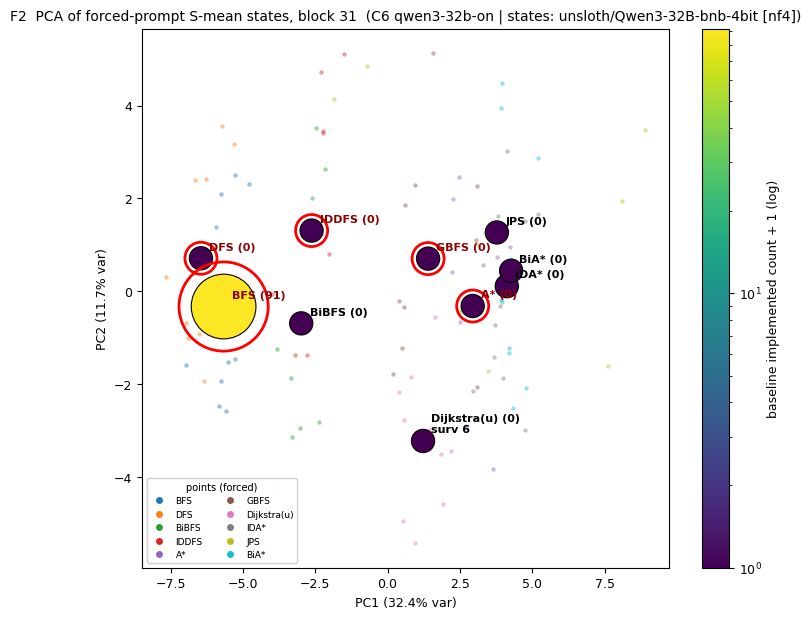

[F3_mds_C6_nf4]


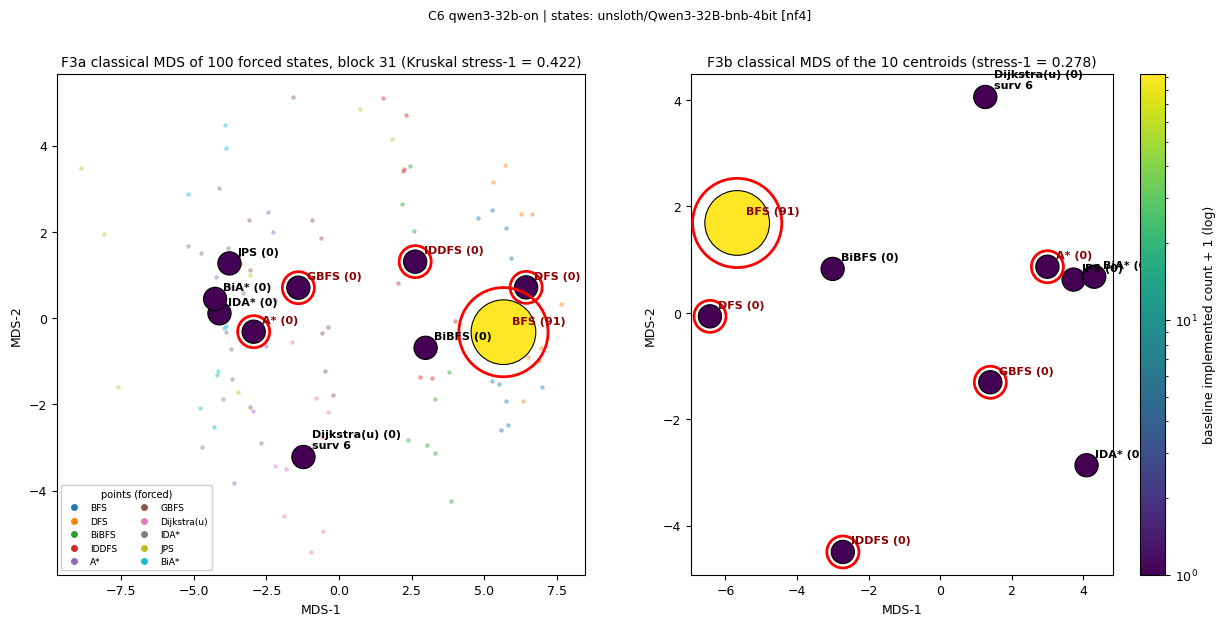

[F4_isomap_C6_nf4]


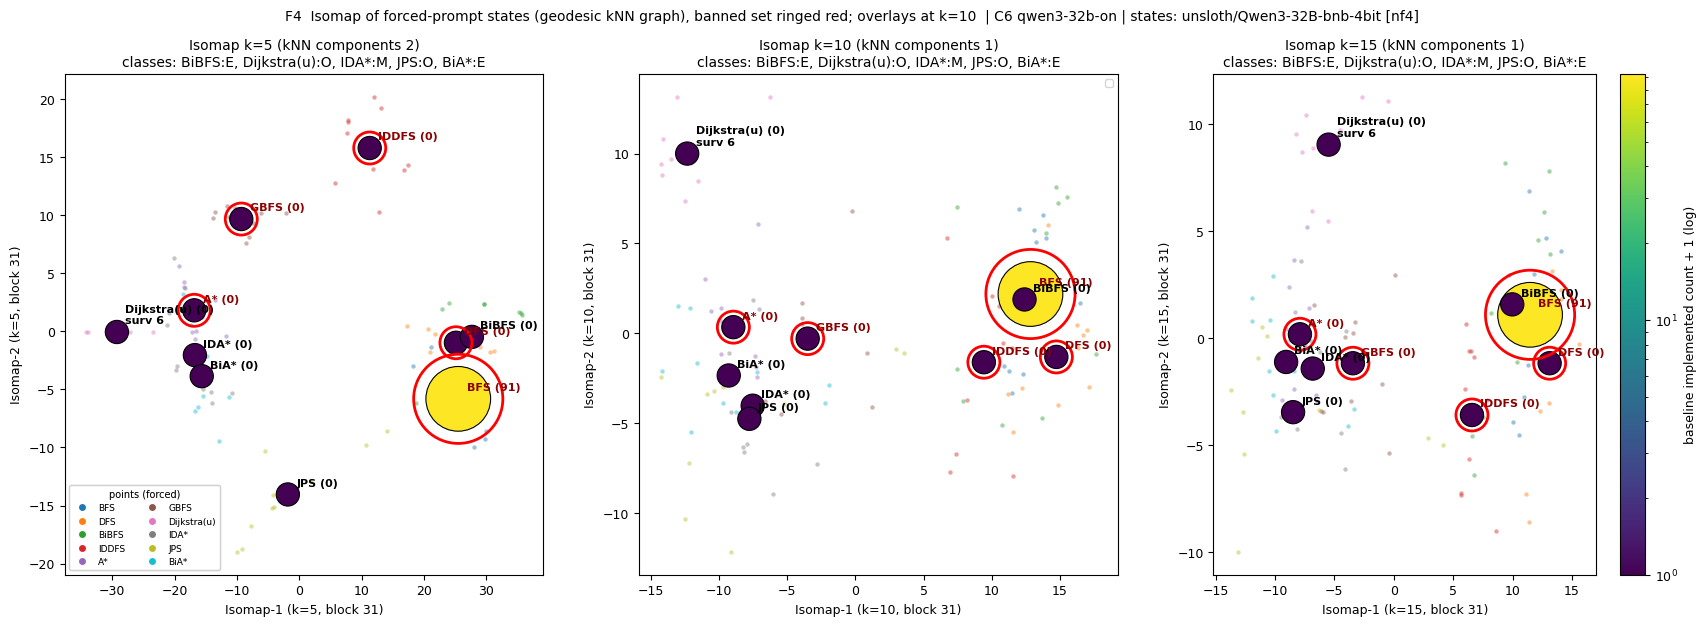

[F6_landing_nulls_C6]


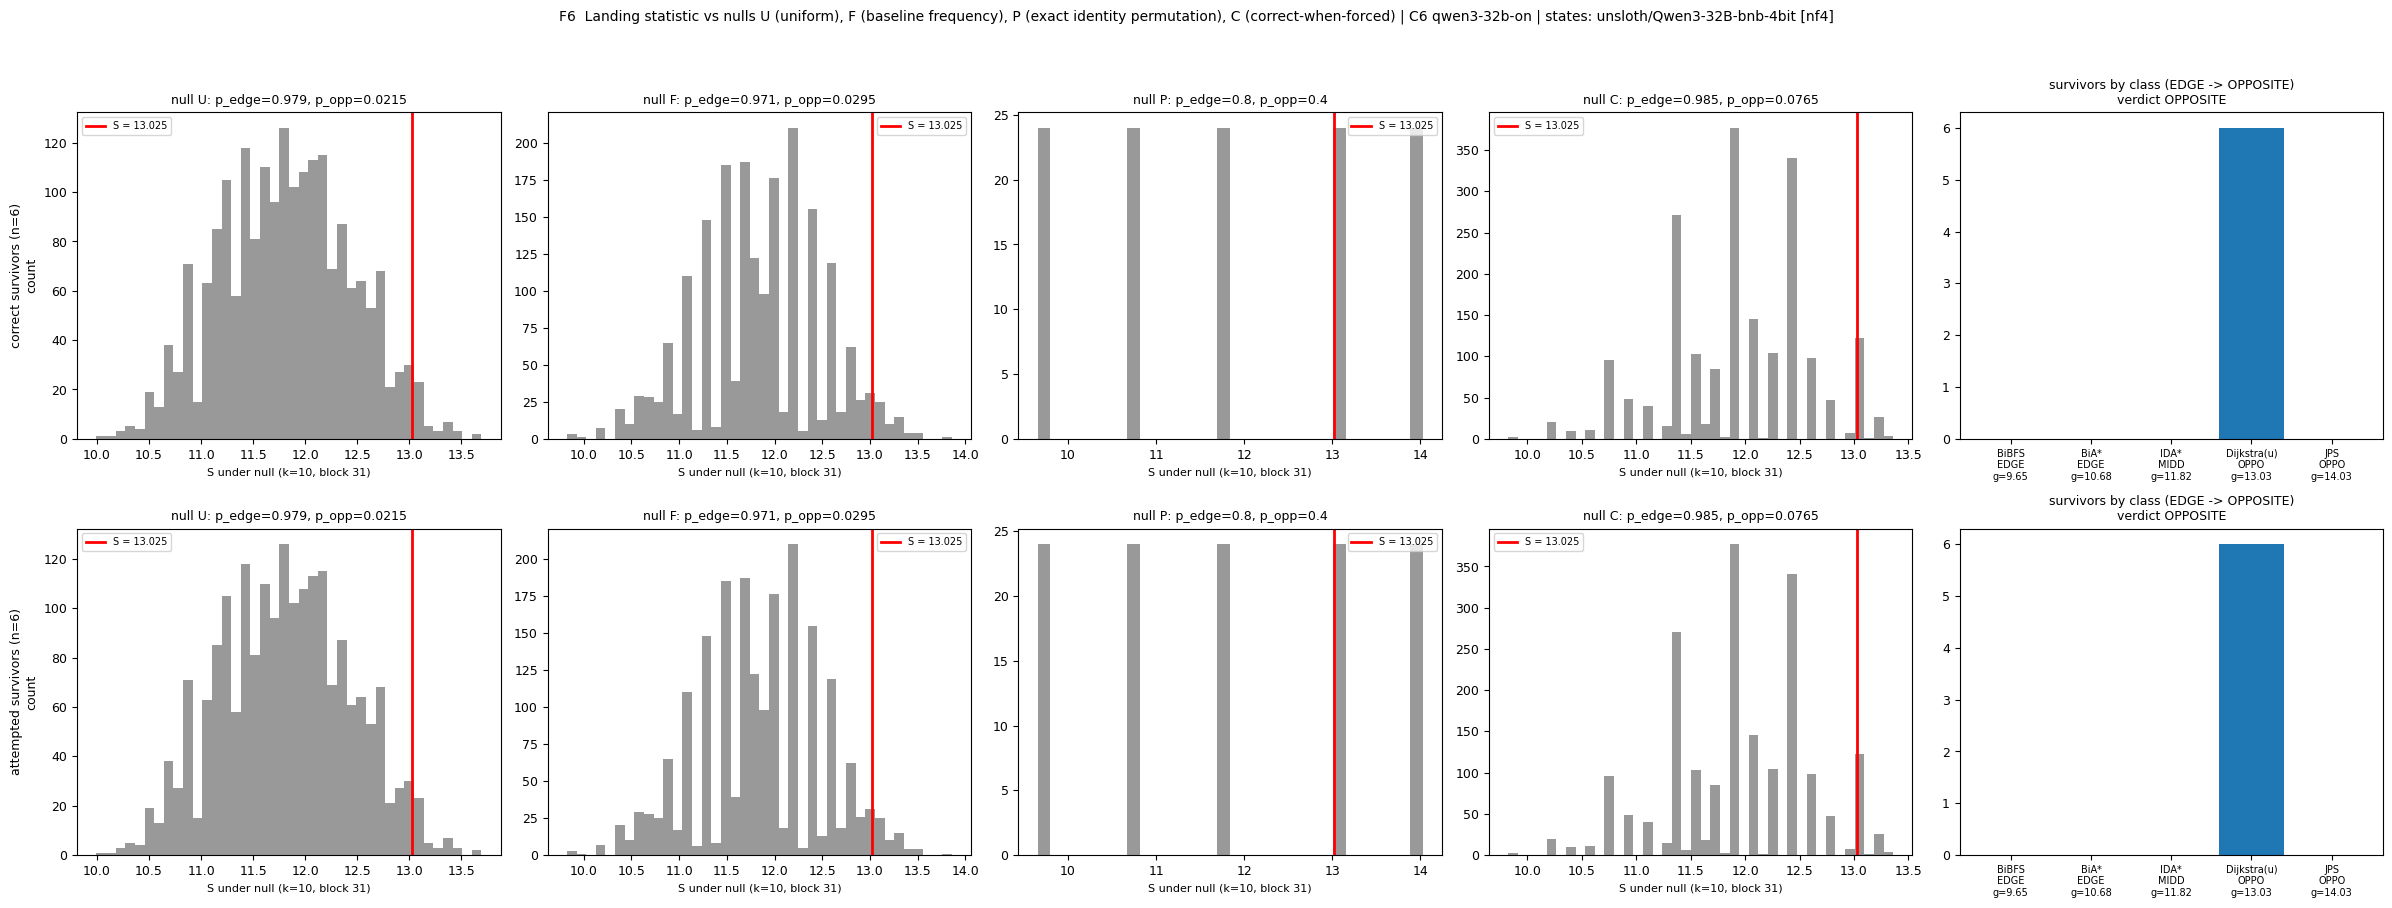

geometry stage finished in 9.5s


In [23]:
manifold_figures(m, X, labels, banned, impl, over, L, kp, ms, tag, surv, att)
if land.get("_nulls_raw") or land_att.get("_nulls_raw"):
    null_figure(land, land_att, m[f"k{kp}"], ms, L, kp)
# original also saved the three geodesic matrices:
# np.savez_compressed(RESULTS.parent / "cache" / "states" / f"geo_{tag}.npz", geo_k5=..., geo_k10=..., geo_k15=..., labels=labels, L=L)
print(f"geometry stage finished in {time.time() - T_STAGE:.1f}s")

## 8. Results: demo subset vs the full run

The demo runs the original stage code on 100 of the 300 forced points: one alias per template instead of three. Two things move as a result:
- **The kNN graph gets denser in label space.** With 10 points per algorithm, an Isomap neighbourhood of k = 10-15 reaches into other algorithms. Absolute g values shrink, and the primary-k rule can pick a different k. In the full run k = 10 was disconnected, so the primary k was 15.
- **The noise floor rises.** The robustness and permutation results are less certain.

The table compares the quantities that carry the claim: the layer, the classes, the survivors' landing and the robustness count. The figure shows the class-level geodesic geometry and how far each non-banned algorithm sits from the banned five, demo against full run.

quantity                              |                      demo subset |                         full run
-----------------------------------------------------------------------------------------------------------
forced points                         |                              100 |                              300
layer L* (blocks scanned)             |                    31 (3 blocks) |                   31 (27 blocks)
CV balanced accuracy at L*            |                             1.00 |                             1.00
PCA EVR PC1 / PC2                     |                    0.324 / 0.117 |                    0.324 / 0.120
MDS stress-1 points / centroids       |                      0.42 / 0.28 |                      0.42 / 0.28
kNN components k=5 / 10 / 15          |                        2 / 1 / 1 |                        8 / 3 / 1
primary k                             |                               10 |                               15
split-half Spearman k=5 / 10

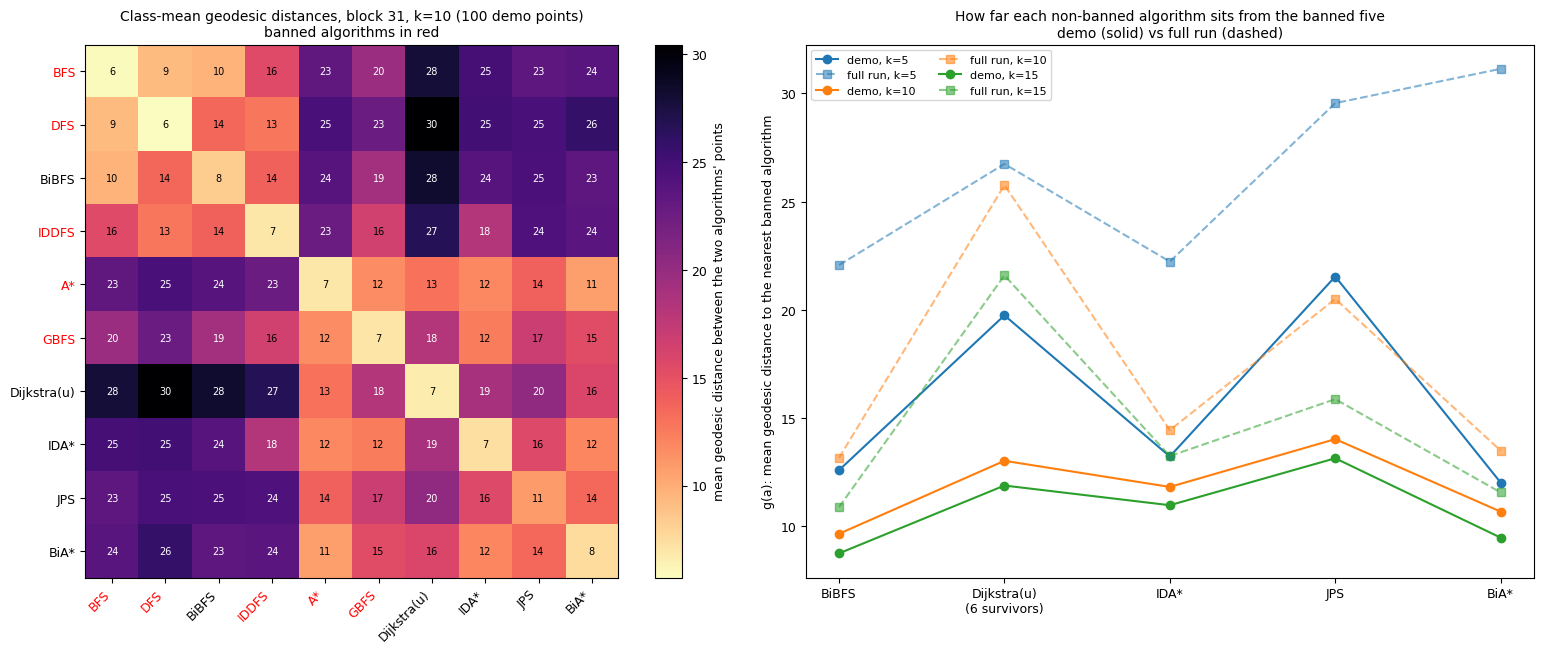

In [24]:
# ---- demo subset vs full run (full-run values from results/geometry_M1.json, landing*.json in the artifact) ----
ref = meta["full_run_reference"]
rk = ref["per_k"]
table = [
    ("forced points", f"{len(X)}", f"{ref['n_points']}"),
    ("layer L* (blocks scanned)", f"{L} ({len(sel_b)} blocks)", f"{ref['L_star']} ({len(ref['layer_curve'])} blocks)"),
    ("CV balanced accuracy at L*", f"{lc['curve'][L]:.2f}", f"{ref['layer_curve'][str(ref['L_star'])]:.2f}"),
    ("PCA EVR PC1 / PC2", f"{m['pca_evr'][0]:.3f} / {m['pca_evr'][1]:.3f}",
     f"{ref['pca_evr_2'][0]:.3f} / {ref['pca_evr_2'][1]:.3f}"),
    ("MDS stress-1 points / centroids", f"{m['mds_points_stress1']:.2f} / {m['mds_centroids_stress1']:.2f}",
     f"{ref['mds_points_stress1']:.2f} / {ref['mds_centroids_stress1']:.2f}"),
    ("kNN components k=5 / 10 / 15", " / ".join(str(m[f"k{k}"]["components_before_join"]) for k in (5, 10, 15)),
     " / ".join(str(rk[f"k{k}"]["components_before_join"]) for k in (5, 10, 15))),
    ("primary k", f"{kp}", f"{ref['k_primary']}"),
    ("split-half Spearman k=5 / 10 / 15", " / ".join(f"{rel['split_half'][k]['spearman_offdiag']:.2f}" for k in (5, 10, 15)),
     " / ".join(f"{ref['split_half_spearman'][str(k)]:.2f}" for k in (5, 10, 15))),
]
for a in nonb:
    table.append((f"k=15 class of {SHORT[a]} (g)", f"{m['k15']['classes'][a]} ({m['k15']['g'][a]:.2f})",
                  f"{rk['k15']['classes'][a]} ({rk['k15']['g'][a]:.2f})"))
table += [
    ("catalogue survivors", str(dict(collections.Counter(surv))), str(dict(collections.Counter(ref["landing"]["survivors"])))),
    ("landing S at primary k", f"{land['S']:.2f} (k={kp})", f"{ref['landing']['S']:.2f} (k={ref['landing']['k']})"),
    ("p_opp under U / F / P / C", " / ".join(f"{land['nulls'][q]['p_opp']:.3g}" for q in "UFPC"),
     " / ".join(f"{ref['landing']['nulls'][q]['p_opp']:.3g}" for q in "UFPC")),
    ("landing verdict (primary)", land["verdict"], ref["landing"]["verdict"]),
    ("verdict attempted / euclid / std", f"{land_att['verdict']} / {land_euc['verdict']} / {land_std['verdict']}",
     f"{ref['landing']['attempted_verdict']} / {ref['landing']['euclid_centroid_verdict']} / "
     f"{ref['landing']['standardised_verdict']}"),
    ("robustness: cells = primary", f"{rob['identical_to_primary']}/{rob['n_cells']} (ROBUST={rob['ROBUST']})",
     f"{ref['robustness']['identical_to_primary']}/{ref['robustness']['n_cells']} (ROBUST={ref['robustness']['ROBUST']})"),
    ("bootstrap class stability Dijkstra(u)", f"{rel['bootstrap']['class_stability']['dijkstra_unit']:.2f} (n={N_BOOT})",
     f"{ref['bootstrap_class_stability']['dijkstra_unit']:.2f} (n=1000)"),
]
w = max(len(r[0]) for r in table)
print(f"{'quantity':{w}s} | {'demo subset':>32s} | {'full run':>32s}")
print("-" * (w + 70))
for q, d_, f_ in table:
    print(f"{q:{w}s} | {d_:>32s} | {f_:>32s}")

# ---- class-level geodesic geometry + distance of each non-banned algorithm from the banned five ----
fig, axs = plt.subplots(1, 2, figsize=(16, 6.4))
Mk = np.array(m[f"k{kp}"]["class_geodesic_matrix"])
im = axs[0].imshow(Mk, cmap="magma_r")
axs[0].set_xticks(range(10))
axs[0].set_xticklabels([SHORT[a] for a in CANON_ORDER], rotation=45, ha="right")
axs[0].set_yticks(range(10))
axs[0].set_yticklabels([SHORT[a] for a in CANON_ORDER])
for tl in (axs[0].get_xticklabels(), axs[0].get_yticklabels()):
    for i, t in enumerate(tl):
        if CANON_ORDER[i] in banned:
            t.set_color("red")
for i in range(10):
    for j in range(10):
        axs[0].text(j, i, f"{Mk[i, j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if Mk[i, j] > np.nanmean(Mk) else "black")
fig.colorbar(im, ax=axs[0]).set_label("mean geodesic distance between the two algorithms' points")
axs[0].set_title(f"Class-mean geodesic distances, block {L}, k={kp} ({len(X)} demo points)\nbanned algorithms in red")
xs = np.arange(len(nonb))
for j, k in enumerate((5, 10, 15)):
    axs[1].plot(xs, [m[f"k{k}"]["g"][a] for a in nonb], "o-", color=CMAP(j), label=f"demo, k={k}")
    axs[1].plot(xs, [rk[f"k{k}"]["g"][a] for a in nonb], "s--", color=CMAP(j), alpha=0.55, label=f"full run, k={k}")
axs[1].set_xticks(xs)
axs[1].set_xticklabels([SHORT[a] + (f"\n({collections.Counter(surv)[a]} survivors)" if a in surv else "") for a in nonb])
axs[1].set_ylabel("g(a): mean geodesic distance to the nearest banned algorithm")
axs[1].set_title("How far each non-banned algorithm sits from the banned five\ndemo (solid) vs full run (dashed)")
axs[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

## Takeaways and how to scale up

**Behaviour.**
- Under a literal five-name ban, only Qwen3-32B with thinking on writes a correct program outside the banned set often enough (17/50) to clear the pre-registered bar.
- Most of its survivors are known algorithms outside the 10-algorithm catalogue: Bellman-Ford/SPFA, random-priority search, a random walk, wavefront propagation. The 6 catalogue survivors are all unit-weight Dijkstra.
- Obeying is expensive: reasoning gets longer and truncation becomes far more frequent.

**Geometry.**
- Which algorithm a prompt forces is linearly decodable from the S-mean state at every middle block.
- On the Isomap geometry at L\* = 31, unit-weight Dijkstra, the only catalogue algorithm the model writes under the ban, lies on the *opposite* side from the banned five, not at their edge. The pre-registered EDGE prediction fails.
- This is a correlational description: in iteration 7, pushes along the manifold changed 0/300 programs.
- With a single landing algorithm, the algorithm-level evidence (null P) cannot fall below p = 0.2.
- The demo subset reproduces the class structure. Its primary k, permutation p and robustness count differ, which shows how sensitive those quantities are to the kNN scale.

**Scaling.** The config cell starts at the minimum. The original loop sizes, `N_BOOT = 1000`, `NULL_DRAWS = 10000`, `ROBUST_DRAWS = 4000` and `LAYER_SCAN_BLOCKS = [29, 30, 31, 32, 33]`, run within a couple of minutes on CPU. The full 300-point analysis with the 27-block layer scan needs the artifact's 181 MB `cache/states/smean_C6_nf4.npz`. To run it, use `uv run method.py geometry` in the original repository; regenerating that file needs `uv run method.py states` and a 16 GB GPU.